In [8]:
import pandas as pd

from matplotlib import pyplot as plt
import seaborn as sns

In [2]:
from pathlib import Path

PROJECT_ROOT = next(
    (p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src/AHO_train.py").is_file()),
    Path("/home/iaw/DATA2/AAReact"),
)
PREDICTION_DIR = PROJECT_ROOT / "train" / "predictions" / "Data_All2"
data = pd.read_csv(PREDICTION_DIR / "data_all2_ddg_predictions_annotated.csv")


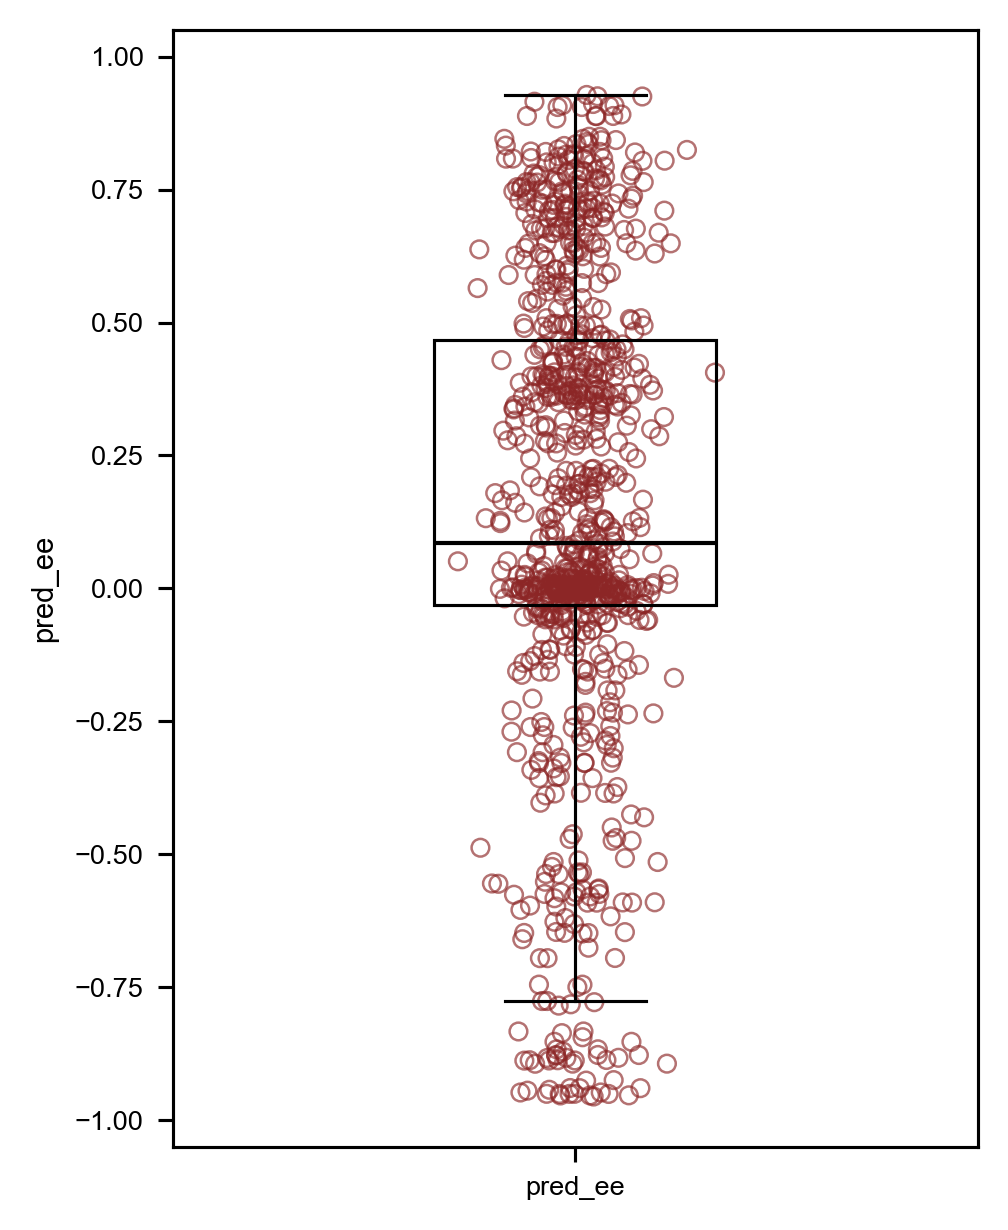

In [14]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.family'] = ['Arial']
plt.rcParams['axes.linewidth'] = 0.75
plt.rcParams['xtick.major.width'] = 0.75
plt.rcParams['ytick.major.width'] = 0.75
plt.rcParams['axes.grid'] = False
plt.rcParams['figure.dpi'] = 300

vals = data["pred_ee"].dropna().values
fig, ax = plt.subplots(figsize=(3.46, 4.2))

np.random.seed(42)
x_jitter = np.random.normal(loc=1, scale=0.045, size=len(vals))

# ========= 第一步：先画散点（底层，全部点不受遮挡） =========
ax.scatter(
    x_jitter, vals,
    s=18,
    facecolor="none",
    edgecolor="#8c2626",
    linewidth=0.6,
    alpha=0.65
)

# ========= 第二步：绘制箱线，无填充！只有边框 =========
box = ax.boxplot(
    vals,
    patch_artist=True,
    showfliers=False,
    widths=0.35,
    medianprops={"color":"black", "linewidth":1.0},
    boxprops={"facecolor":"none", "edgecolor":"black", "linewidth":0.75}, # 关键：无填充
    whiskerprops={"color":"black", "linewidth":0.75},
    capprops={"color":"black", "linewidth":0.75}
)

ax.set_xticks([1])
ax.set_xticklabels(["pred_ee"], fontsize=7)
ax.set_ylabel("pred_ee", fontsize=7)
ax.tick_params(axis='both', labelsize=6.5)
ax.set_ylim(-1.05, 1.05)
ax.set_yticks([-1, -0.75, -0.5, -0.25, 0, 0.25, 0.5, 0.75, 1])

plt.tight_layout()
plt.show()
